# Notebook 2: TF-IDF + Logistic Regression Baseline
Trains the baseline on the shared training split, evaluates it on the held-out validation and test split, and saves predictions + metrics so they can be compared with the fine-tuned DistilBERT.

**Inputs:** `headlines_train.csv`, `headlines_test.csv`, `headlines_validation.csv`

**Outputs:** `tfidf_lr_predictions.csv`, `tfidf_lr_metrics.json`, `tfidf_lr_confusion_matrix.png`, `tfidf_lr.joblib` (for the demo notebook)

**Label convention (same as the cleaned data):** 0 = non-clickbait, 1 = clickbait. Clickbait is the positive class for precision, recall and F1.

## 0. Setup

In [1]:
import os, json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

pd.set_option("display.max_colwidth", 120)

TRAIN_PATH = "headlines_train.csv"
VALIDATION_PATH  = "headlines_validation.csv"
TEST_PATH  = "headlines_test.csv"
OUT_DIR    = "results/tfidf_lr"       # every output file goes in this folder
SEED       = 42                      # fixed so results are reproducible
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load the shared train/test split
If the files aren't in Colab yet, the cell will ask you to upload them. Do not make your own split,
 both models must use Member 1's exact files so the comparison is fair.

In [2]:
missing = [p for p in (TRAIN_PATH, TEST_PATH, VALIDATION_PATH) if not os.path.exists(p)]
if missing:
    from google.colab import files
    print("Please upload:", missing)
    files.upload()

# utf-8-sig because the previous notebook saved the files with a BOM (so Excel shows text correctly)
train_df = pd.read_csv(TRAIN_PATH, encoding="utf-8-sig")
validation_df  = pd.read_csv(VALIDATION_PATH,  encoding="utf-8-sig")
test_df  = pd.read_csv(TEST_PATH,  encoding="utf-8-sig")
print("Train:", train_df.shape, "| Validation:", validation_df.shape, "| Test:", test_df.shape)
train_df.head()

Train: (40208, 2) | Validation: (5027, 2) | Test: (5026, 2)


,headline,label
0,Everything Donald Trump Looked Like In 2015,1
1,Ahmed Fahour hits back at Hanson: 'Does she have an issue with the colour of my skin?' – video,0
2,"Elena Delle Donne to Mystics: Latest Trade Details, Comments and Reaction",0
3,The 14 Worst Things People Have Put In Their Mouths,1
4,Hurricane Humberto messes with forecasters and Texas,0


## 2. Sanity checks
Confirms these are the right files: expected shapes are **(40208, 2)** for train, **(5027, 2)** for validation, and **(5026, 2)** for test, with about 60.8% non-clickbait / 39.2% clickbait in all of them.

In [3]:
for name, d in (("train", train_df), ("validation", test_df), ("test", test_df)):
    assert list(d.columns[:2]) == ["headline", "label"], f"{name}: unexpected columns {list(d.columns)}"
    assert d["headline"].notna().all(), f"{name}: missing headlines"
    assert d["label"].isin([0, 1]).all(), f"{name}: labels must be 0/1"

print("Train label share:\n", train_df["label"].value_counts(normalize=True).round(3))
print("Validation label share:\n", validation_df["label"].value_counts(normalize=True).round(3))
print("\nTest label share:\n", test_df["label"].value_counts(normalize=True).round(3))

# No headline may appear in both splits (that would leak test data into training)
assert not set(train_df["headline"]) & set(validation_df["headline"]) & set(test_df["headline"]), "Leakage: headline in splits!"
print("\nNo headline overlap between train and test.")

# Separate the text (X) from the answer (y)
X_train, y_train = train_df["headline"].astype(str), train_df["label"].astype(int)
X_validation, y_validation = validation_df["headline"].astype(str), validation_df["label"].astype(int)
X_test,  y_test  = test_df["headline"].astype(str),  test_df["label"].astype(int)

Train label share:
 label
0    0.608
1    0.392
Name: proportion, dtype: float64
Validation label share:
 label
0    0.608
1    0.392
Name: proportion, dtype: float64

Test label share:
 label
0    0.608
1    0.392
Name: proportion, dtype: float64

No headline overlap between train and test.


## 3. Train the baseline (TF-IDF + Logistic Regression)
- **TF-IDF** turns each headline into numbers based on which words/word-pairs it contains and how distinctive they are.
- **Logistic Regression** learns which of those features point to clickbait.

The vectorizer sits **inside** the pipeline, so the vocabulary is learned from the training data only. Settings are fixed and not tuned on the test set.

In [4]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),     # single words and two-word phrases
        min_df=2,               # ignore words seen in fewer than 2 headlines
        sublinear_tf=True)),    # dampen very frequent words
    ("clf", LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)),
])

model.fit(X_train, y_train)     # learns from the TRAINING data only
print("Training done. Vocabulary size:", len(model.named_steps["tfidf"].vocabulary_))

Training done. Vocabulary size: 53572


## 4. Validate on the validation set
Before touching the test set, the trained model is checked on `headline_validation.csv`. The model is not trained or tuned on these headlines, so this is only a quick check that it works on unseen data. The final results reported for the comparison still come from the test set.

In [5]:
val_pred = model.predict(X_validation)
val_cm = confusion_matrix(y_validation, val_pred, labels=[0, 1])

print(f"\nValidation accuracy            : {accuracy_score(y_validation, val_pred):.4f}")
print(f"Validation clickbait precision : {precision_score(y_validation, val_pred, pos_label=1):.4f}")
print(f"Validation clickbait recall    : {recall_score(y_validation, val_pred, pos_label=1):.4f}")
print(f"Validation clickbait F1-score  : {f1_score(y_validation, val_pred, pos_label=1):.4f}")

print("\nValidation confusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(val_cm, index=["true non-clickbait", "true clickbait"],
                   columns=["pred non-clickbait", "pred clickbait"]))


Validation accuracy            : 0.9005
Validation clickbait precision : 0.9026
Validation clickbait recall    : 0.8366
Validation clickbait F1-score  : 0.8684

Validation confusion matrix (rows = true class, columns = predicted class):
                    pred non-clickbait  pred clickbait
true non-clickbait                2878             178
true clickbait                     322            1649


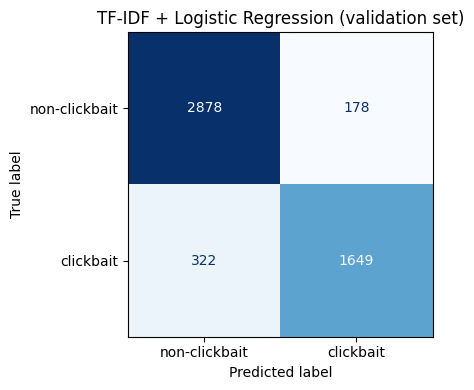

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(val_cm, display_labels=["non-clickbait", "clickbait"]).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("TF-IDF + Logistic Regression (validation set)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/tfidf_lr_confusion_matrix_validation_set.png", dpi=150)
plt.show()

## 5. Evaluate on the held-out test set
The model has never seen these headlines, so this shows how well it works on new data. Predictions use the default 0.5 threshold.

In [7]:
y_pred = model.predict(X_test)                  # predicted class (0 or 1)
y_prob = model.predict_proba(X_test)[:, 1]      # P(clickbait), later used for the 0–100% score

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])   # [[TN, FP], [FN, TP]]
tn, fp, fn, tp = cm.ravel()

metrics = {
    "model": "TF-IDF + Logistic Regression",
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "threshold": 0.5,
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "clickbait_precision": float(precision_score(y_test, y_pred, pos_label=1)),
    "clickbait_recall": float(recall_score(y_test, y_pred, pos_label=1)),
    "clickbait_f1": float(f1_score(y_test, y_pred, pos_label=1)),
    "confusion_matrix": cm.tolist(),
    "confusion_matrix_labels": ["non_clickbait(0)", "clickbait(1)"],
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
}

print(f"Accuracy            : {metrics['accuracy']:.4f}")
print(f"Clickbait precision : {metrics['clickbait_precision']:.4f}")
print(f"Clickbait recall    : {metrics['clickbait_recall']:.4f}")
print(f"Clickbait F1-score  : {metrics['clickbait_f1']:.4f}")

print("\nConfusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(cm, index=["true non-clickbait", "true clickbait"],
                   columns=["pred non-clickbait", "pred clickbait"]))

print("\nFull report:")
print(classification_report(y_test, y_pred, target_names=["non-clickbait", "clickbait"], digits=4))

Accuracy            : 0.8828
Clickbait precision : 0.8851
Clickbait recall    : 0.8056
Clickbait F1-score  : 0.8435

Confusion matrix (rows = true class, columns = predicted class):
                    pred non-clickbait  pred clickbait
true non-clickbait                2850             206
true clickbait                     383            1587

Full report:
               precision    recall  f1-score   support

non-clickbait     0.8815    0.9326    0.9063      3056
    clickbait     0.8851    0.8056    0.8435      1970

     accuracy                         0.8828      5026
    macro avg     0.8833    0.8691    0.8749      5026
 weighted avg     0.8829    0.8828    0.8817      5026



### 6. Confusion matrix plot (for the report)

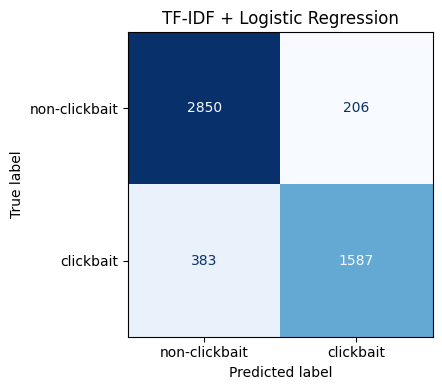

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["non-clickbait", "clickbait"]).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("TF-IDF + Logistic Regression")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/tfidf_lr_confusion_matrix.png", dpi=150)
plt.show()

## 7. Save predictions, metrics and the model
- Predictions keep the **same row order as `headlines_test.csv`**, so they can be lined up with DistilBERT's.
- Metric names (`accuracy`, `clickbait_precision`, `clickbait_recall`, `clickbait_f1`, `confusion_matrix`) should be reused by Member 3 so the results match.
- `tfidf_lr.joblib` is the full pipeline (vectorizer + model) that Member 1's demo notebook loads.

In [9]:
preds = pd.DataFrame({
    "row_id": np.arange(len(test_df)),   # position in headlines_test.csv
    "headline": test_df["headline"].values,
    "y_true": y_test.values,
    "y_pred": y_pred,
    "prob_clickbait": y_prob,            # x100 gives the proposed 0–100% score
})
preds.to_csv(f"{OUT_DIR}/tfidf_lr_predictions.csv", index=False, encoding="utf-8-sig")

with open(f"{OUT_DIR}/tfidf_lr_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

joblib.dump(model, f"{OUT_DIR}/tfidf_lr.joblib")

print("Saved to", OUT_DIR + "/:", sorted(os.listdir(OUT_DIR)))
preds.head()

Saved to results/tfidf_lr/: ['tfidf_lr.joblib', 'tfidf_lr_confusion_matrix.png', 'tfidf_lr_confusion_matrix_validation_set.png', 'tfidf_lr_metrics.json', 'tfidf_lr_predictions.csv']


,row_id,headline,y_true,y_pred,prob_clickbait
0,0,15 Cringeworthy Romance Stories That'll Make You Glad You're Single,1,1,0.985972
1,1,Singles Try To Explain Cuffing Season,1,0,0.462781
2,2,"From 'smaller grapes, still a great bunch' to wine branded, 'for the table, not the cellar': Sainsbury's Basics rang...",0,0,0.349590
3,3,New York City Welcomes Drake's Third OVO Flagship Store,0,0,0.098069
4,4,Pearson Acquires Stake in 2 Indian Education Companies,0,0,0.100431


## 8. Download files to share with Members 1 & 3
- `tfidf_lr_predictions.csv` and `tfidf_lr_metrics.json` → Member 3 (comparison)
- `tfidf_lr.joblib` → Member 1 (demo notebook)
- `tfidf_lr_confusion_matrix.png` → for the report

In [10]:
try:
    from google.colab import files
    for f in sorted(os.listdir(OUT_DIR)):
        files.download(os.path.join(OUT_DIR, f))
except ImportError:
    print("Not in Colab, files are in the folder:", OUT_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>